In [1]:
import os
import sys

module_path = os.path.join(os.getcwd(), '..', 'module')
sys.path.append(module_path)

from Data_preparation import data_for_clust
from Data_preparation import quantity_executors
from Data_preparation import quantity_all
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import DBSCAN

import pandas as pd
# pd.set_option('display.float_format', '{:,.2f}'.format)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

from sklearn.cluster import KMeans, MeanShift, AgglomerativeClustering

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

In [2]:
#Загружаем исходные данные 
not_changed_df = pd.read_excel('../../data/Финал_клин.xlsx', 'Финальная таблица')

not_changed_df['ИНН исполнителя'] = not_changed_df['ИНН исполнителя'].apply(
        lambda x: f"{int(x):.0f}" if pd.notna(x) else ''
    )

not_changed_df.head()

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков,ОКВЭД,Доходы,Расходы,Прибыль(убыток)
0,2780804522025000020,7820303220,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""КЛИН...",Исполнение завершено,3.722002e+17,11.08.2025,30.09.2025,139890.00,139890.00,NaN,NaN,Нет,нет,Деятельность по чистке и уборке жилых зданий и...,14820000.0,14414000.0,406000.0
1,2782200215525000008,782031876507,БАРАБАНОВ ИГОРЬ СЕРГЕЕВИЧ Индивидуальный предп...,Исполнение завершено,3.722001e+17,25.02.2025,31.12.2025,45028.80,45028.80,NaN,NaN,Нет,нет,Предоставление социальных услуг без обеспечени...,NaN,NaN,NaN
2,2782544053425000023,782031876507,БАРАБАНОВ ИГОРЬ СЕРГЕЕВИЧ Индивидуальный предп...,Исполнение завершено,3.722001e+17,12.05.2025,31.12.2025,981363.80,981363.80,NaN,NaN,Нет,нет,Предоставление социальных услуг без обеспечени...,NaN,NaN,NaN
3,2782544053424000058,782031876507,БАРАБАНОВ ИГОРЬ СЕРГЕЕВИЧ Индивидуальный предп...,Исполнение завершено,3.722001e+17,04.06.2024,31.12.2024,1019797.77,1019797.77,NaN,NaN,Нет,нет,Предоставление социальных услуг без обеспечени...,NaN,NaN,NaN
4,2780503024025000210,781617676312,ЧЕКРЕНЕВ ИГОРЬ АЛЕКСАНДРОВИЧ Индивидуальный пр...,Исполнение завершено,3.721000e+17,16.06.2025,15.12.2025,397013.75,397013.75,NaN,NaN,Нет,нет,Производство электромонтажных работ,NaN,NaN,NaN


In [3]:
#Создаем данные для кластеризации в R
first_df = data_for_clust('../../data/Финал_клин.xlsx', 'Финальная таблица')

first_df = first_df.drop(0).reset_index(drop=True)

clust_data = first_df[['ИНН исполнителя', 'Средняя цена контракта', 'Количество контрактов']]

clust_data = clust_data.copy()

clust_data['Средняя цена контракта log'] = np.log(clust_data['Средняя цена контракта'])
clust_data['Количество контрактов log'] = np.log(clust_data['Количество контрактов'])

clust_data_new = clust_data.drop(['Средняя цена контракта', 'ИНН исполнителя', 'Количество контрактов'], axis=1)

In [4]:
clust_data.describe()

,Средняя цена контракта,Количество контрактов,Средняя цена контракта log,Количество контрактов log
count,2.860000e+02,286.000000,286.000000,286.000000
mean,2.957331e+06,3.454545,13.742793,0.750974
std,6.148321e+06,5.180567,1.656013,0.874388
min,7.806000e+03,1.000000,8.962648,0.000000
25%,3.525095e+05,1.000000,12.772758,0.000000
50%,1.098354e+06,2.000000,13.909292,0.693147
75%,2.496720e+06,4.000000,14.730488,1.386294
max,6.744398e+07,46.000000,18.026808,3.828641


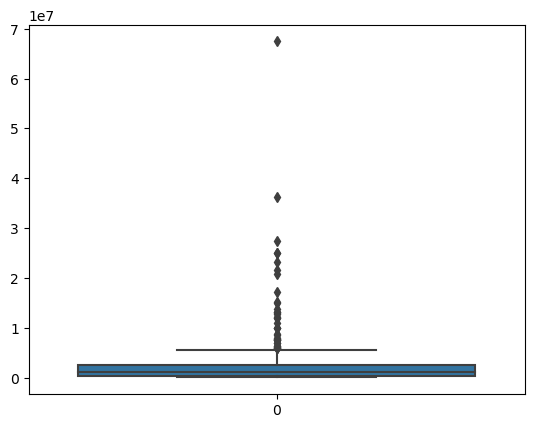

In [5]:
#Графики выбросов
sns.boxplot(clust_data["Средняя цена контракта"])
plt.show()


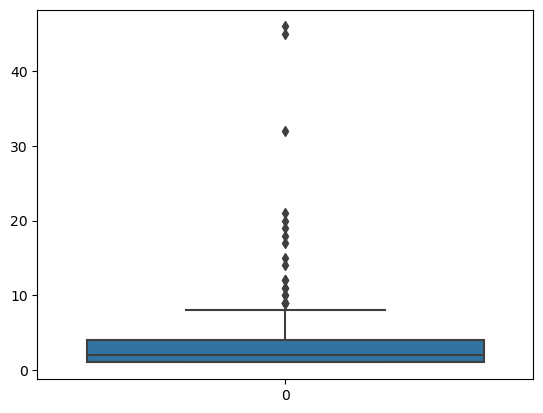

In [6]:
sns.boxplot(clust_data["Количество контрактов"])
plt.show()

In [7]:
# df_no_outliers = clust_data
# for i in range(7):
    
#     Q1 = df_no_outliers['Средняя цена контракта'].quantile(0.25)
#     Q3 = df_no_outliers['Средняя цена контракта'].quantile(0.75)
#     IQR = Q3 - Q1

#     low = Q1 - 1.5 * IQR
#     high = Q3 + 1.5 * IQR

#     df_no_outliers = clust_data[(clust_data['Средняя цена контракта'] >= low) & (clust_data['Средняя цена контракта'] <= high)]
    

In [8]:

# for j in range(3):
    
#     Q1_2 = df_no_outliers['Количество контрактов'].quantile(0.25)
#     Q3_2 = df_no_outliers['Количество контрактов'].quantile(0.75)
#     IQR_2 = Q3_2 - Q1_2

#     low_2 = Q1_2 - 1.5 * IQR_2
#     high_2 = Q3_2 + 1.5 * IQR_2

#     df_no_outliers = df_no_outliers[(df_no_outliers['Количество контрактов'] >= low_2) & (df_no_outliers['Количество контрактов'] <= high_2)]

In [9]:
def winsorize_df(df, cols, low=0.25, high=0.75):
    df_out = df.copy()
    for c in cols:
        ql, qh = df_out[c].quantile([low, high])
        df_out[c] = df_out[c].clip(ql, qh)
    return df_out

df_no_outliers = winsorize_df(clust_data, ['Средняя цена контракта'], 0.15, 0.85)
df_no_outliers = winsorize_df(df_no_outliers, ['Количество контрактов'], 0.05, 0.95)


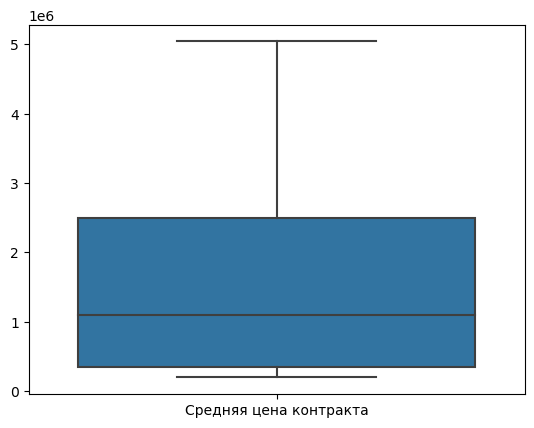

In [10]:
# df_no_outliers = clust_data
sns.boxplot(df_no_outliers[["Средняя цена контракта"]])
plt.show()

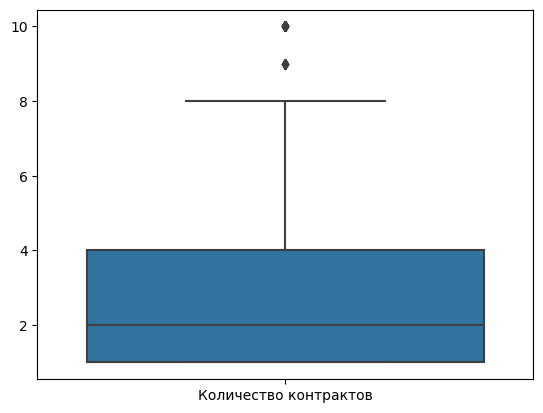

In [11]:
sns.boxplot(df_no_outliers[["Количество контрактов"]])
plt.show()

In [12]:
df_no_outliers.describe()

,Средняя цена контракта,Количество контрактов,Средняя цена контракта log,Количество контрактов log
count,2.860000e+02,286.000000,286.000000,286.000000
mean,1.731142e+06,2.919580,13.742793,0.750974
std,1.673433e+06,2.710053,1.656013,0.874388
min,1.954952e+05,1.000000,8.962648,0.000000
25%,3.525095e+05,1.000000,12.772758,0.000000
50%,1.098354e+06,2.000000,13.909292,0.693147
75%,2.496720e+06,4.000000,14.730488,1.386294
max,5.041153e+06,10.000000,18.026808,3.828641


In [13]:
#Стандартизация

In [14]:
df_no_outliers.iloc[ :,1:]

,Средняя цена контракта,Количество контрактов,Средняя цена контракта log,Количество контрактов log
0,8.014710e+05,8,13.594204,2.079442
1,2.904975e+06,1,14.881935,0.000000
2,3.080916e+06,2,14.940737,0.693147
3,1.954952e+05,1,11.794033,0.000000
4,3.953414e+05,2,12.887505,0.693147
...,...,...,...,...
281,1.323615e+06,10,14.095877,2.833213
282,1.971323e+05,2,12.191630,0.693147
283,2.022905e+06,1,14.520045,0.000000
284,5.041153e+06,1,15.515432,0.000000


In [15]:
scaler = MinMaxScaler()
scaled = df_no_outliers.copy()
scaled_2 = clust_data.copy()

scaled.iloc[:, 1:] = scaler.fit_transform(scaled.iloc[:, 1:])
scaled_2.iloc[:, 1:] = scaler.fit_transform(scaled_2.iloc[:, 1:])

df_scaled = pd.DataFrame(scaled, columns=df_no_outliers.columns)
df_scaled_2 = pd.DataFrame(scaled_2, columns=clust_data.columns)

In [16]:
#Иерархическая кластеризация
from scipy.cluster.hierarchy import dendrogram, linkage
from matplotlib import pyplot as plt

In [17]:
#Матрица слияний для необработанных занчений
# Z = linkage(df_scaled[["Средняя цена контракта", "Количество контрактов"]], method='ward', metric='euclidean', optimal_ordering=True)

Z = linkage(df_scaled_2[["Средняя цена контракта log", "Количество контрактов log"]], method='ward', metric='euclidean', optimal_ordering=True)

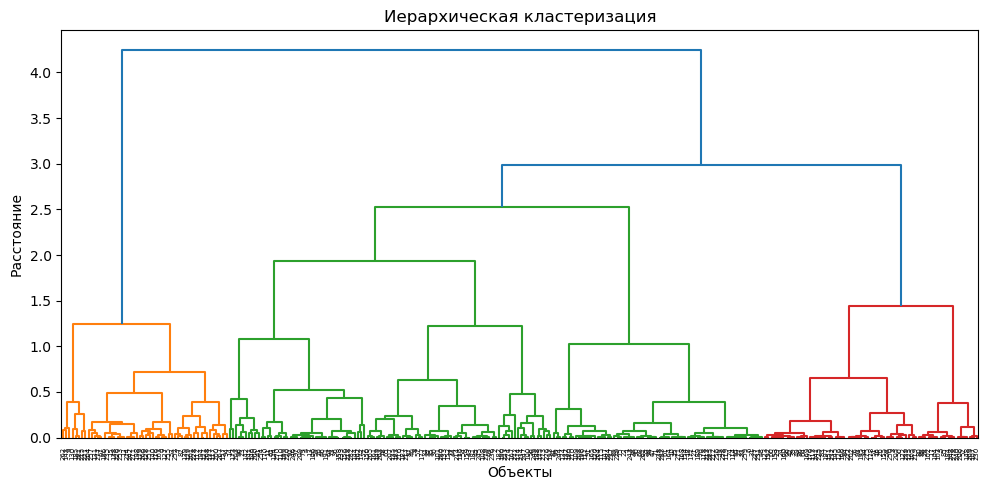

In [18]:
plt.figure(figsize=(10, 5))
dendrogram(Z, leaf_rotation=90)
plt.title("Иерархическая кластеризация")
plt.xlabel("Объекты")
plt.ylabel("Расстояние")
plt.tight_layout()
plt.show()

In [19]:
k = 5
labels_k = fcluster(Z, t=k, criterion='maxclust')

In [20]:
df_hc = clust_data.copy()
df_hc['Cluster'] = labels_k

summary = df_hc.groupby('Cluster')[["Средняя цена контракта", "Количество контрактов"]].agg(['mean','count'])
print(summary)

        Средняя цена контракта       Количество контрактов      
                          mean count                  mean count
Cluster                                                         
1                 2.686259e+06    52             10.500000    52
2                 3.168323e+05    43              3.441860    43
3                 6.550146e+06    58              2.775862    58
4                 4.458772e+06    66              1.000000    66
5                 2.731323e+05    67              1.000000    67


In [21]:
df_hc.describe()

,Средняя цена контракта,Количество контрактов,Средняя цена контракта log,Количество контрактов log,Cluster
count,2.860000e+02,286.000000,286.000000,286.000000,286.000000
mean,2.957331e+06,3.454545,13.742793,0.750974,3.185315
std,6.148321e+06,5.180567,1.656013,0.874388,1.420623
min,7.806000e+03,1.000000,8.962648,0.000000,1.000000
25%,3.525095e+05,1.000000,12.772758,0.000000,2.000000
50%,1.098354e+06,2.000000,13.909292,0.693147,3.000000
75%,2.496720e+06,4.000000,14.730488,1.386294,4.000000
max,6.744398e+07,46.000000,18.026808,3.828641,5.000000


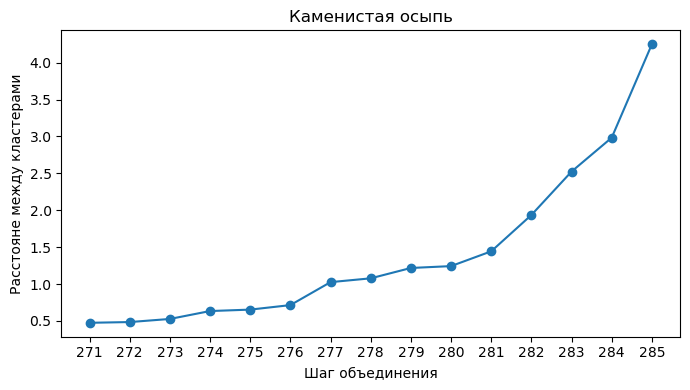

In [22]:
heights = Z[:, 2]
steps = np.arange(1, len(heights)+1)

last = 15
sel = np.arange(len(heights)-last, len(heights))
plt.figure(figsize=(7,4))
plt.plot(sel+1, heights[sel], marker='o')
plt.title("Каменистая осыпь")
plt.xlabel("Шаг объединения")
plt.ylabel("Расстояне между кластерами")
plt.xticks(sel + 1)
plt.tight_layout()
plt.show()

In [23]:
clust_data_with_labels = pd.concat(
    [clust_data[["ИНН исполнителя", "Средняя цена контракта", "Количество контрактов"]]
    .reset_index(drop=True), 
    pd.DataFrame(labels_k, columns=["Cluster"])
    .reset_index(drop=True)], 
    axis = 1)

In [24]:
clust_data_with_labels.describe()

,Средняя цена контракта,Количество контрактов,Cluster
count,2.860000e+02,286.000000,286.000000
mean,2.957331e+06,3.454545,3.185315
std,6.148321e+06,5.180567,1.420623
min,7.806000e+03,1.000000,1.000000
25%,3.525095e+05,1.000000,2.000000
50%,1.098354e+06,2.000000,3.000000
75%,2.496720e+06,4.000000,4.000000
max,6.744398e+07,46.000000,5.000000


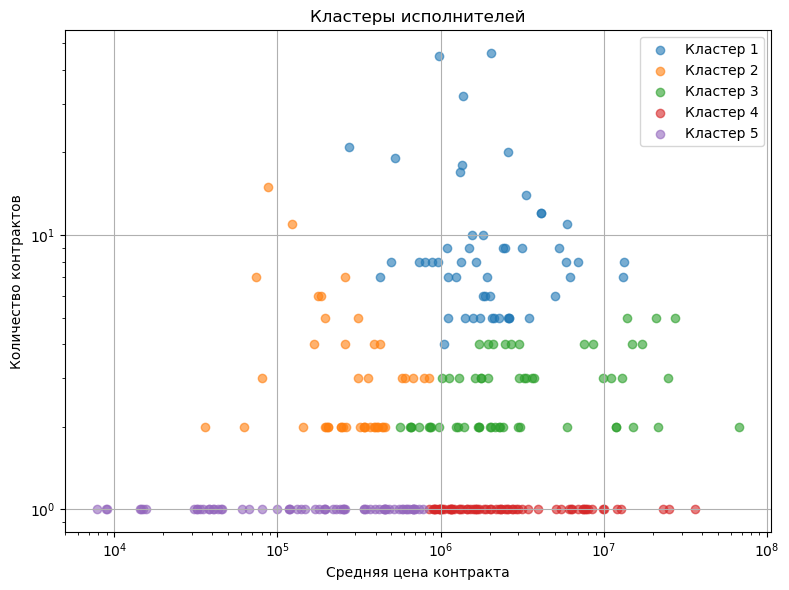

In [25]:

plt.figure(figsize=(8, 6))

for cl in sorted(clust_data_with_labels["Cluster"].unique()):
    subset = clust_data_with_labels[clust_data_with_labels["Cluster"] == cl]
    plt.scatter(subset["Средняя цена контракта"],
                subset["Количество контрактов"],
                alpha=0.6,
                label=f"Кластер {cl}")

plt.xscale("log")  
plt.yscale("log")    
    
plt.xlabel("Средняя цена контракта")
plt.ylabel("Количество контрактов")
plt.title("Кластеры исполнителей")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [26]:
#Для обработанных данных
Z_no_outliers = linkage(df_scaled[["Средняя цена контракта", "Количество контрактов"]], method='ward', metric='euclidean', optimal_ordering=True)

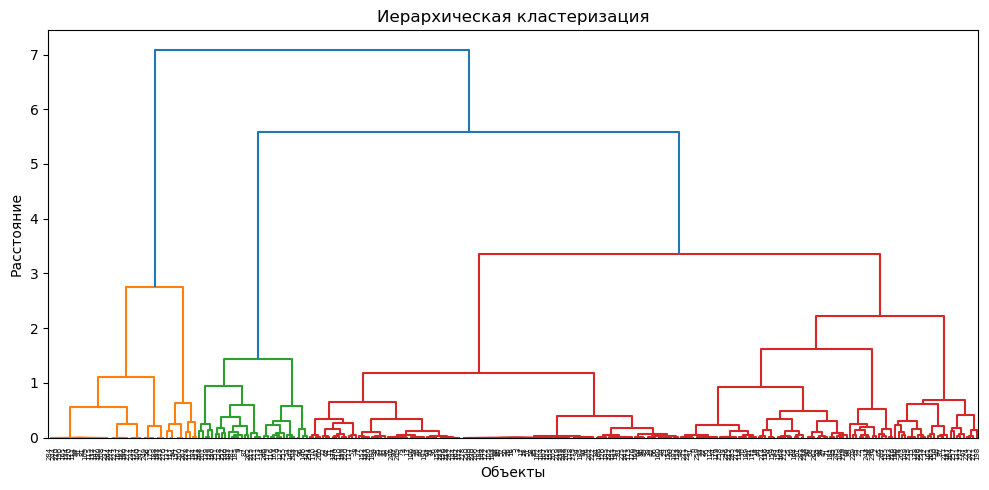

In [27]:
plt.figure(figsize=(10, 5))
dendrogram(Z_no_outliers, leaf_rotation=90)
plt.title("Иерархическая кластеризация")
plt.xlabel("Объекты")
plt.ylabel("Расстояние")
plt.tight_layout()
plt.show()

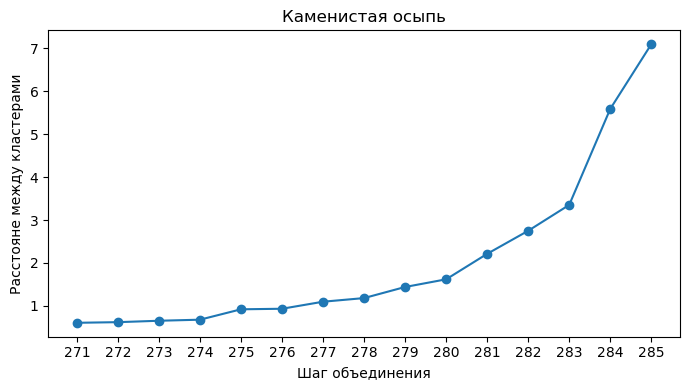

In [28]:
heights = Z_no_outliers[:, 2]
steps = np.arange(1, len(heights)+1)

last = 15
sel = np.arange(len(heights)-last, len(heights))
plt.figure(figsize=(7,4))
plt.plot(sel+1, heights[sel], marker='o')
plt.title("Каменистая осыпь")
plt.xlabel("Шаг объединения")
plt.ylabel("Расстояне между кластерами")
plt.xticks(sel + 1)
plt.tight_layout()
plt.show()

In [29]:
k_2 = 3
labels_k_2 = fcluster(Z_no_outliers, t=k_2, criterion='maxclust')

In [30]:
df_hc_2 = df_no_outliers.copy()
df_hc_2['Cluster'] = labels_k_2

summary = df_hc_2.groupby('Cluster')[["Средняя цена контракта", "Количество контрактов"]].agg(['mean','count'])
print(summary)

        Средняя цена контракта       Количество контрактов      
                          mean count                  mean count
Cluster                                                         
1                 5.000656e+06    46              3.413043    46
2                 1.152671e+06    34              8.470588    34
3                 1.096532e+06   206              1.893204   206


In [31]:
no_outliers_data_with_labels = pd.concat(
    [df_no_outliers[["ИНН исполнителя", "Средняя цена контракта", "Количество контрактов"]]
    .reset_index(drop=True), 
    pd.DataFrame(labels_k_2, columns=["Cluster"])
    .reset_index(drop=True)], 
    axis = 1)


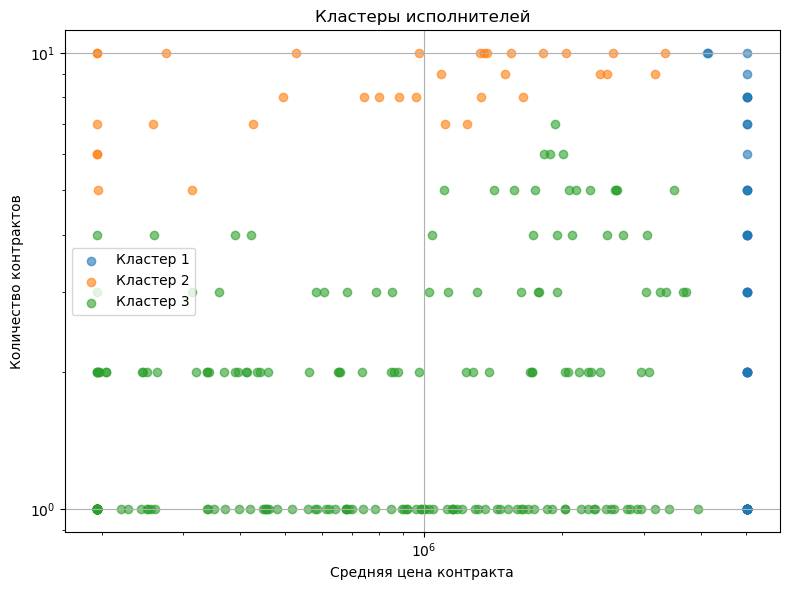

In [32]:

plt.figure(figsize=(8, 6))

for cl in sorted(no_outliers_data_with_labels["Cluster"].unique()):
    subset = no_outliers_data_with_labels[no_outliers_data_with_labels["Cluster"] == cl]
    plt.scatter(subset["Средняя цена контракта"],
                subset["Количество контрактов"],
                alpha=0.6,
                label=f"Кластер {cl}")

plt.xscale("log")  
plt.yscale("log")    
    
plt.xlabel("Средняя цена контракта")
plt.ylabel("Количество контрактов")
plt.title("Кластеры исполнителей")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [33]:
clust_data_ex = clust_data.copy()
clust_data_ex = clust_data_ex.drop(['Средняя цена контракта log', 'Количество контрактов log'], axis = 1)
clust_data_ex.head()

clust_data_ex.to_excel('Здания для кластеризации 2.xlsx', index=False)

In [34]:
#Загружаем результаты кластеризации 
clusters_df = pd.read_excel('../R/результаты_кластеризации.xlsx')

clusters_df.columns = [c.replace(".", " ") for c in clusters_df.columns]

clusters_df = clusters_df[["ИНН исполнителя", "Cluster"]]

In [35]:
#Выводим общие данные 
print(quantity_all(not_changed_df))

Общее количество контрактов: 1000
Общая сумма контрактов: 2956463209.59
Общее количество исполнителей: 287
None


In [36]:
#Подготовка сборного датасета

similarity_df = first_df.drop(["Сумма контрактов", "Сумма оплат"], axis = 1)

similarity = similarity_df.copy()

similarity['Рентабельность продаж'] = (( \
    similarity['Прибыль(убыток)'] / similarity['Доходы']) \
    .where(similarity['ИНН исполнителя'].astype(str).str.len() == 10)) \
    .replace([np.inf, -np.inf, np.nan], 0)

similarity['Доля прекращенных контрактов'] = (similarity['Количество прекращенных контрактов'] / similarity['Количество контрактов']) \
    .replace([np.inf, -np.inf, np.nan], 0)
    
similarity['Доля штрафных контрактов'] = (similarity['Неустойки (штрафы и пени)'] / similarity['Количество контрактов']) \
    .replace([np.inf, -np.inf, np.nan], 0)
    
similarity['Доля контракта от доходов'] = (( \
    similarity['Средняя цена контракта'] / similarity['Доходы']) \
    .where(similarity['ИНН исполнителя'].astype(str).str.len() == 10)) \
    .replace([np.inf, -np.inf, np.nan], 0)

similarity['Доля оплаты от цены контракта'] = (
    similarity['Средняя сумма оплат'] / similarity['Средняя цена контракта']
    )

fin_cols = ["Прибыль(убыток)", "Доля контракта от доходов", "Рентабельность продаж"]
similarity["Прибыль(убыток)"] = np.log1p(similarity["Прибыль(убыток)"])

scaler = MinMaxScaler()
df_fin_scaled = pd.DataFrame(scaler.fit_transform(similarity[fin_cols]), columns = fin_cols)

# similarity["Финансовая устойчивость"] = df_fin_scaled.mean(axis = 1)


#Удаление столбцов чтобы избежать дублирования при join-е
similarity = similarity.drop([
                             "Доходы", "Расходы", "Прибыль(убыток)",
                             "Включение в реестр недобросовестных поставщиков"], axis = 1)

C:\Users\Alexander\anaconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [37]:
#Подготовка данных 
clusters_df["ИНН исполнителя"] = clusters_df["ИНН исполнителя"].astype("object")

clusters_df['ИНН исполнителя'] = (
    clusters_df['ИНН исполнителя']
    .astype(str)                           
    .str.strip()                            
    .str.replace(r'\.0$', '', regex=True)   
    .str.replace(r'\D', '', regex=True)    
)

In [38]:
df_hc = df_hc[["ИНН исполнителя","Cluster"]]
df_hc_2 = df_hc_2[["ИНН исполнителя","Cluster"]]

In [39]:
full_df = pd.merge(not_changed_df, similarity, on="ИНН исполнителя", how="left")
full_df = pd.merge(full_df, df_hc, on="ИНН исполнителя", how="left")



In [40]:
full_df.describe()

,Реестровый номер контракта,Номер извещения,Цена контракта,Фактически оплачено,Доходы,Расходы,Прибыль(убыток),Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Cluster
count,1.000000e+03,9.800000e+02,1.000000e+03,9.570000e+02,4.860000e+02,4.860000e+02,4.860000e+02,9.880000e+02,9.880000e+02,9.780000e+02,988.000000,988.000000,988.000000,988.000000,988.000000,988.000000,988.000000,978.000000,988.000000
mean,2.479872e+18,3.445041e+17,2.956463e+06,2.819366e+06,6.429823e+07,5.827397e+07,6.024260e+06,2.847025e+06,6.612276e+06,2.664341e+06,11.196356,2.393725,1.496964,-0.014585,0.218623,0.112348,0.186972,0.930276,1.947368
std,4.990972e+17,1.327338e+17,7.011518e+06,6.856570e+06,9.451631e+07,9.018083e+07,1.091166e+07,5.134015e+06,1.149421e+07,4.794692e+06,12.896907,4.032774,3.475342,1.825208,0.271966,0.194882,1.410361,0.144656,1.261728
min,1.470000e+18,1.451000e+17,2.688800e+02,2.688800e+02,0.000000e+00,0.000000e+00,-4.759000e+06,7.806000e+03,7.806000e+03,3.931440e+03,1.000000,0.000000,0.000000,-56.854839,0.000000,0.000000,0.000000,0.015682,1.000000
25%,1.783000e+18,3.452000e+17,3.798690e+05,3.259865e+05,1.403800e+07,1.229500e+07,2.960000e+05,5.824534e+05,1.159007e+06,5.289566e+05,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.917681,1.000000
50%,2.780705e+18,3.722000e+17,1.252350e+06,1.098904e+06,3.646800e+07,2.529300e+07,2.005000e+06,1.373345e+06,2.999963e+06,1.332212e+06,7.000000,1.000000,0.000000,0.000000,0.090909,0.000000,0.000000,0.992370,1.000000
75%,2.781605e+18,3.722002e+17,2.686902e+06,2.539267e+06,7.220925e+07,7.052600e+07,7.966000e+06,2.573887e+06,6.907343e+06,2.573887e+06,12.500000,3.000000,1.000000,0.063745,0.391304,0.200000,0.049327,1.000000,3.000000
max,4.784029e+18,8.725000e+17,9.235670e+07,9.103919e+07,1.066776e+09,1.058850e+09,8.906200e+07,6.744398e+07,9.235670e+07,6.127358e+07,46.000000,18.000000,16.000000,0.991066,1.000000,1.000000,23.022845,1.253872,5.000000


In [41]:
# full_df = full_df.dropna(subset=["ИНН исполнителя"])
# full_df = full_df[full_df["ИНН исполнителя"].str.strip() != ""]
# full_df = full_df.reset_index(drop=True)

full_df = full_df.dropna(subset=["ИНН исполнителя"])
full_df = full_df.dropna(subset=["Cluster"])
full_df = full_df[full_df["ИНН исполнителя"].str.strip() != ""]
full_df = full_df.reset_index(drop=True)

In [42]:
full_df["Статус контракта"] = (full_df["Статус контракта"] == "Исполнение завершено").astype(int)

full_df["Включение в реестр недобросовестных поставщиков"] = (full_df["Включение в реестр недобросовестных поставщиков"] == "да").astype(int)

In [43]:
full_df["ЛогЦена"] = np.log1p(full_df["Цена контракта"].clip(lower=0))
full_df["ЛогПрибыль"] = np.log1p(full_df["Прибыль(убыток)"].clip(lower=0))
# full_df["Доля оплаты"] = full_df["Фактически оплачено"]/full_df["Цена контракта"]

scaler = MinMaxScaler()

cols_to_scale = ["ЛогЦена", "ЛогПрибыль"]

full_df[cols_to_scale] = scaler.fit_transform(full_df[cols_to_scale])


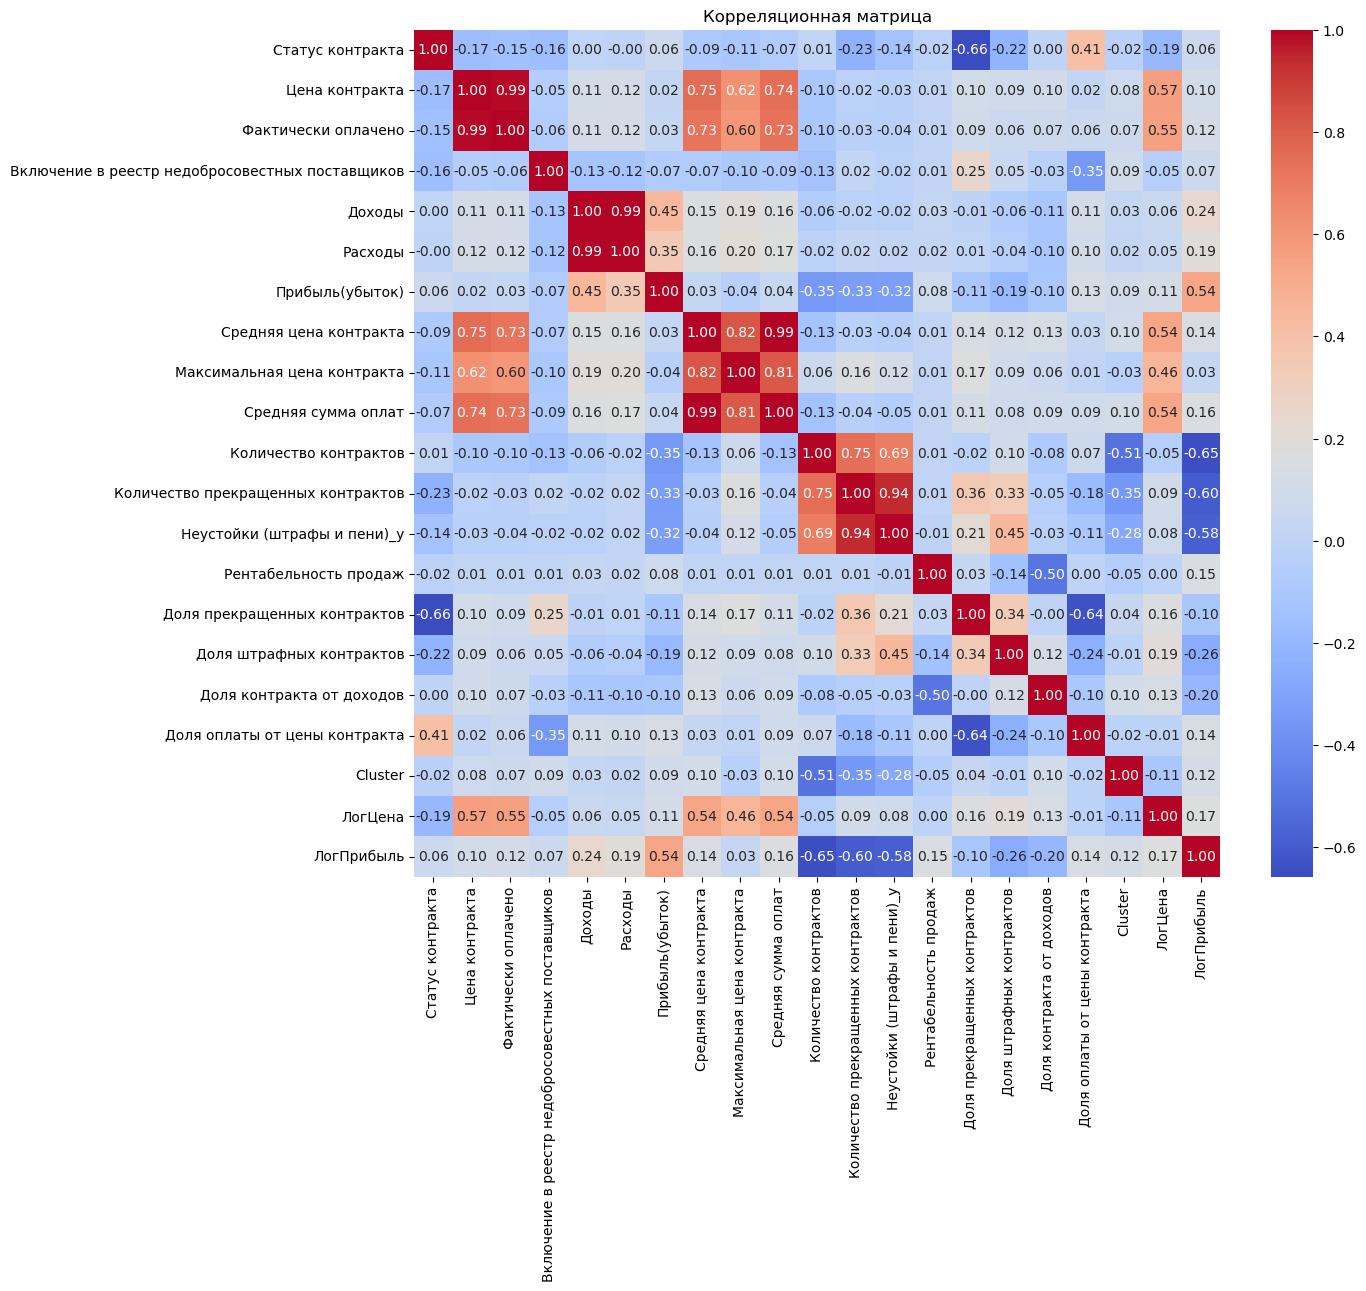

In [44]:
numeric_df = full_df.select_dtypes(include=["number"])
numeric_df = numeric_df.drop(["Реестровый номер контракта", "Номер извещения"], axis = 1)

corr_matrix = numeric_df.corr()

plt.figure(figsize=(13,11))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Корреляционная матрица")
plt.show()

In [45]:
full_df = pd.get_dummies(full_df, columns = ["Cluster"], drop_first = True)

In [46]:
full_df

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,ОКВЭД,Доходы,Расходы,Прибыль(убыток),Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,ЛогЦена,ЛогПрибыль,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0
0,2780804522025000020,7820303220,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""КЛИН...",1,3.722002e+17,11.08.2025,30.09.2025,139890.00,139890.00,NaN,NaN,Нет,0,Деятельность по чистке и уборке жилых зданий и...,14820000.0,14414000.0,406000.0,1.398900e+05,139890.00,1.398900e+05,1.0,0.0,0.0,0.027395,0.0,0.0,0.009439,1.000000,0.490508,0.705502,0,0,0,1
1,2782200215525000008,782031876507,БАРАБАНОВ ИГОРЬ СЕРГЕЕВИЧ Индивидуальный предп...,1,3.722001e+17,25.02.2025,31.12.2025,45028.80,45028.80,NaN,NaN,Нет,0,Предоставление социальных услуг без обеспечени...,NaN,NaN,NaN,1.332212e+06,3242999.41,1.332212e+06,8.0,0.0,0.0,0.000000,0.0,0.0,0.000000,1.000000,0.401556,NaN,0,0,0,0
2,2782544053425000023,782031876507,БАРАБАНОВ ИГОРЬ СЕРГЕЕВИЧ Индивидуальный предп...,1,3.722001e+17,12.05.2025,31.12.2025,981363.80,981363.80,NaN,NaN,Нет,0,Предоставление социальных услуг без обеспечени...,NaN,NaN,NaN,1.332212e+06,3242999.41,1.332212e+06,8.0,0.0,0.0,0.000000,0.0,0.0,0.000000,1.000000,0.643381,NaN,0,0,0,0
3,2782544053424000058,782031876507,БАРАБАНОВ ИГОРЬ СЕРГЕЕВИЧ Индивидуальный предп...,1,3.722001e+17,04.06.2024,31.12.2024,1019797.77,1019797.77,NaN,NaN,Нет,0,Предоставление социальных услуг без обеспечени...,NaN,NaN,NaN,1.332212e+06,3242999.41,1.332212e+06,8.0,0.0,0.0,0.000000,0.0,0.0,0.000000,1.000000,0.646395,NaN,0,0,0,0
4,2780503024025000210,781617676312,ЧЕКРЕНЕВ ИГОРЬ АЛЕКСАНДРОВИЧ Индивидуальный пр...,1,3.721000e+17,16.06.2025,15.12.2025,397013.75,397013.75,NaN,NaN,Нет,0,Производство электромонтажных работ,NaN,NaN,NaN,3.970138e+05,397013.75,3.970138e+05,1.0,0.0,0.0,0.000000,0.0,0.0,0.000000,1.000000,0.572365,NaN,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
983,1770982726620001181,7801531045,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ВОСХ...",0,8.724000e+17,07.12.2020,31.12.2021,25067504.12,NaN,Односторонний отказ заказчика от исполнения ко...,Неисполнение обязательств по государственному ...,Да,0,Деятельность прочего сухопутного пассажирского...,NaN,NaN,NaN,2.506750e+07,25067504.12,NaN,1.0,1.0,1.0,0.000000,1.0,1.0,0.000000,NaN,0.897664,NaN,0,0,1,0
984,1781448847821000003,781415901903,КУЗНЕЦОВ ЕВГЕНИЙ ВЛАДИМИРОВИЧ Индивидуальный п...,0,3.451000e+17,24.12.2020,31.12.2021,1734818.70,144568.22,Соглашение сторон,Соглашение сторон,Нет,0,Деятельность автомобильного грузового транспорта,NaN,NaN,NaN,1.277409e+06,1734818.70,1.285529e+05,2.0,2.0,0.0,0.000000,1.0,0.0,0.000000,0.100636,0.688088,NaN,0,1,0,0
985,1783806756721000002,7805756850,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ЗВЕЗ...",0,1.724000e+17,30.12.2020,31.07.2021,353847.03,NaN,Односторонний отказ заказчика от исполнения ко...,"Существенное нарушение исполнения Контракта, в...",Да,0,Деятельность по чистке и уборке жилых зданий и...,NaN,NaN,NaN,1.968512e+05,353847.03,1.806467e+05,5.0,2.0,2.0,0.000000,0.4,0.4,0.000000,0.917681,0.563332,NaN,1,0,0,0
986,1783806756721000001,7805756850,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ЗВЕЗ...",0,1.724000e+17,30.12.2020,31.07.2021,88469.02,NaN,Односторонний отказ заказчика от исполнения ко...,"Существенное нарушение исполнения Контракта, в...",Да,0,Деятельность по чистке и уборке жилых зданий и...,NaN,NaN,NaN,1.968512e+05,353847.03,1.806467e+05

In [47]:
#Модели

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [49]:
#Переменные 

features = [
        'Фактически оплачено',
        'Количество контрактов',
        'Количество прекращенных контрактов',
        'ЛогЦена'
#         'Cluster_2.0'
#         'Cluster_3.0'
#         'Cluster_4.0',
#         'Cluster_5.0'
    ]


scaler = MinMaxScaler()

full_df[features] = scaler.fit_transform(full_df[features])

X = full_df[features].fillna(0)
y = full_df["Статус контракта"]

In [50]:
#Разбиение даннх

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [51]:
#Random forest
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

model = RandomForestClassifier(
    n_estimators=300,     
    max_depth=15,        
    min_samples_split=2,   
    min_samples_leaf=3,   
    class_weight="balanced", 
    random_state=42           
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_tr = model.predict(X_train)

y_prob = model.predict_proba(X_test)[:, 1]
y_prob_tr = model.predict_proba(X_train)[:, 1]

y_pred_custom = (y_prob >= 0.6).astype(int) 

scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')


print("F1 по фолдам:", scores, "\n")
print("Средний F1:", scores.mean(), "\n")

print("Матрица ошибок:\n", confusion_matrix(y_test, y_pred))
print("\nРезультат классификации:\n", classification_report(y_test, y_pred))
print("\nРезультат классификации дял train:\n", classification_report(y_train, y_pred_tr))
print("\nРезультат классификации с порогом:\n", classification_report(y_test, y_pred_custom))

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nБудущая важность:\n", feature_importance)

F1 по фолдам: [0.88073394 0.93457944 0.92307692 0.91743119 0.91588785 0.91428571
 0.89320388 0.95412844 0.90909091 0.95412844] 

Средний F1: 0.9196546738016942 

Матрица ошибок:
 [[ 54  11]
 [ 21 211]]

Результат классификации:
               precision    recall  f1-score   support

           0       0.72      0.83      0.77        65
           1       0.95      0.91      0.93       232

    accuracy                           0.89       297
   macro avg       0.84      0.87      0.85       297
weighted avg       0.90      0.89      0.89       297


Результат классификации дял train:
               precision    recall  f1-score   support

           0       0.87      0.95      0.91       151
           1       0.98      0.96      0.97       540

    accuracy                           0.96       691
   macro avg       0.93      0.95      0.94       691
weighted avg       0.96      0.96      0.96       691


Результат классификации с порогом:
               precision    recall  f1-score

In [52]:
X_train_prop = X_train.copy()
X_train_prop["probability"] = y_prob_tr

X_test_prop = X_test.copy()
X_test_prop["probability"] = y_prob

X_res = pd.concat([X_train_prop, X_test_prop])

full_df_prob = pd.concat([full_df, X_res["probability"]], axis = 1)

In [53]:
group_full_df_prob = full_df_prob.groupby('ИНН исполнителя', as_index=False).agg(Вероятность_участия=('probability', 'mean'))

group_full_df_prob.drop(0, axis=0, inplace=True)

group_full_df_prob.reset_index(drop=True, inplace=True)

group_full_df_prob.head()

,ИНН исполнителя,Вероятность_участия
0,1001334880,0.024384
1,110110067712,0.997013
2,1101159127,0.998427
3,1435361389,0.173103
4,165118595909,0.997395


In [54]:
group_full_df_prob.sort_values(by = "Вероятность_участия", ascending = False)["Вероятность_участия"].unique()

array([1.        , 0.99962963, 0.99961956, 0.99956106, 0.99947552,
       0.99941511, 0.99939577, 0.99930502, 0.99926889, 0.99920991,
       0.99916667, 0.99898363, 0.99893112, 0.99887129, 0.99869754,
       0.99868318, 0.99862959, 0.99861004, 0.99844223, 0.99842657,
       0.99842095, 0.99838562, 0.99837314, 0.99826392, 0.99820313,
       0.99818731, 0.9981444 , 0.99800256, 0.99791949, 0.99787251,
       0.99786223, 0.99772393, 0.99751029, 0.99739508, 0.99723323,
       0.99719043, 0.99718176, 0.99707555, 0.99707167, 0.99701321,
       0.99679735, 0.99661388, 0.99647774, 0.99644734, 0.99637462,
       0.99631741, 0.99611417, 0.99604954, 0.99573445, 0.99560833,
       0.99558239, 0.99502111, 0.995     , 0.99494721, 0.9945289 ,
       0.99446646, 0.99406507, 0.99333333, 0.99325909, 0.99302073,
       0.99285034, 0.99233009, 0.99223717, 0.99120805, 0.99072841,
       0.99040888, 0.98955945, 0.98851003, 0.98838599, 0.9881227 ,
       0.98764921, 0.98735976, 0.98554707, 0.98536793, 0.98345

In [55]:
first_df_merge_prob = pd.merge(first_df, group_full_df_prob, on = "ИНН исполнителя", how = "left")

In [56]:
probability_df = first_df_merge_prob.loc[first_df_merge_prob["Максимальная цена контракта"]>26000000].sort_values(by = ["Вероятность_участия", "Средняя цена контракта"], ascending = False)

In [57]:
probability_df

,ИНН исполнителя,Сумма контрактов,Средняя цена контракта,Максимальная цена контракта,Сумма оплат,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков,Вероятность_участия
175,7810013071,5.985304e+07,1.496326e+07,30066815.39,5.710486e+07,1.427621e+07,4,154123000.0,137329000.0,16794000.0,0,0,0,0.995021
234,7816274834,3.905837e+07,1.301946e+07,29902782.73,3.829089e+07,1.276363e+07,3,85010000.0,74715000.0,10295000.0,0,1,0,0.992330
81,665209071864,3.632068e+07,3.632068e+07,36320683.85,3.604015e+07,3.604015e+07,1,NaN,NaN,NaN,0,0,0,0.985368
273,7842023467,6.905574e+07,1.381115e+07,35492981.11,6.751298e+07,1.350260e+07,5,224425000.0,219187000.0,5238000.0,2,1,0,0.526868
157,7806272267,1.059515e+08,1.324394e+07,38180356.63,1.052506e+08,1.315632e+07,8,249909000.0,241730000.0,8179000.0,2,0,0,0.490753
276,7842459510,1.040658e+08,2.081316e+07,92356699.83,1.020224e+08,2.040449e+07,5,80677000.0,78251000.0,2426000.0,2,0,0,0.479586
94,772774274560,9.143790e+07,1.306256e+07,26791283.24,9.131812e+07,1.304545e+07,7,NaN,NaN,NaN,3,3,0,0.394872
193,7811548471,1.367130e+08,2.734259e+07,86585771.54,1.133374e+08,2.266749e+07,5,102651000.0,101334000.0,1317000.0,3,0,0,0.349160
174,7810010730,7.484978e+07,2.494993e+07,26597917.69,7.477861e+07,2.492620e+07,3,91183000.0,86107000.0,5076000.0,1,0,0,0.257298
272,7841432932,1.348880e+08,6.744398e+07,70904664.13,1.225472e+08,6.127358e+07,2,113141000.0,110671000.0,2470000.0,1,1,0,0.255372


In [58]:
probability_df[["ИНН исполнителя", "Вероятность_участия"]].reset_index(drop=True)

,ИНН исполнителя,Вероятность_участия
0,7810013071,0.995021
1,7816274834,0.992330
2,665209071864,0.985368
3,7842023467,0.526868
4,7806272267,0.490753
5,7842459510,0.479586
6,772774274560,0.394872
7,7811548471,0.349160
8,7810010730,0.257298
9,7841432932,0.255372
